# 01 — Dane, wycieki i podział

Cała logika jest w `src/data.py`, `src/features.py`, `src/split.py`. Ten notebook tylko je wywołuje.

- Kolumny wykluczone z powodu wycieku: `End_Time` / czas trwania, `End_Lat`, `End_Lng`,
  `Distance(mi)` i pochodne, `Description`.
- Zadanie: 3 klasy — Sev1-2, Sev3, Sev4.
- Podział: `train` i `test_in` (2016–2021, grupy zdarzeń), `test_out` (2022–2023Q1).
- Stare notebooki: `notebooks/archive/`.

In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')
import pandas as pd
pd.set_option('display.precision', 3)
from src.experiment import load_all
from src.data import LEAKY_COLUMNS
from src.evaluate import to_3_classes, CLASS_NAMES
from src import plots

df = load_all()
df['target'] = pd.Categorical.from_codes(to_3_classes(df['Severity'].to_numpy()), CLASS_NAMES)
print(df.shape)
print('Wykluczone kolumny:', LEAKY_COLUMNS)

(1741433, 42)
Wykluczone kolumny: ['End_Time', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description']


## Dryf: etykieta zależy od źródła danych i od okresu

`Source1` od 2021 r. praktycznie nie nadaje klasy 3, a `Source2` nadaje ją ~30–45% zdarzeń.
Udział źródeł zmienia się w czasie, więc rozkład `Severity` w danych zmienia się z roku na rok.

In [2]:
pd.crosstab(df['Source'], df['target'], normalize='index').mul(100).round(1)

target,Sev1-2,Sev3,Sev4
Source,,,
Source1,97.0,1.9,1.1
Source2,60.0,39.8,0.1
Source3,65.3,34.6,0.1


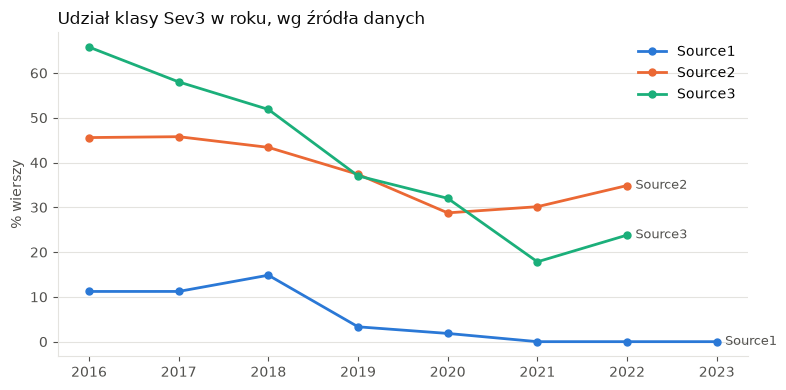

In [3]:
fig = plots.share_by_year(df, 'target', 'Sev3', title='Udział klasy Sev3 w roku, wg źródła danych')

In [4]:
pd.crosstab(df['Year'], df['Source'])

Source,Source1,Source2,Source3
Year,,,
2016,34465,105949,38
2017,35970,113994,2784
2018,35415,116464,5019
2019,108408,89704,15343
2020,211062,57450,17020
2021,265286,70994,5596
2022,338937,32312,4664
2023,74559,0,0


## Podział danych

`train` i `test_in` mają te same proporcje; `test_out` (2022–2023) ma zupełnie inny rozkład klas i źródeł.

In [5]:
summary = pd.crosstab(df['split'], df['target'], normalize='index').mul(100).round(2)
summary['wiersze'] = df['split'].value_counts()
summary['% Source1'] = (df['Source'] == 'Source1').groupby(df['split']).mean().mul(100).round(1)
summary

target,Sev1-2,Sev3,Sev4,wiersze,% Source1
split,,,,,
test_in,79.11,20.10,0.79,193503,53.5
test_out,96.51,2.75,0.75,450472,91.8
train,79.12,20.10,0.79,1097458,53.5


In [6]:
# Kontrola: żadne zdarzenie (duplikaty tego samego wypadku) nie jest w dwóch częściach
print('max liczba części na zdarzenie:', df.groupby('event_id')['split'].nunique().max())

max liczba części na zdarzenie: 1
